In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC104.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [3]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-04-07 13:11:14.842316: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-04-07 13:11:14.842343: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-07 13:11:14.842346: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-04-07 13:11:14.842886: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-07 13:11:14.842906: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [6]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [7]:
base_model = ResNet50(weights='imagenet', 
                      include_top=False, 
                      input_shape=(224, 224, 3))

In [8]:
base_model.trainable = False

In [9]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    layers.Rescaling(1./255),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
   
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Regularization to prevent overfitting
    
    layers.Dense(4, activation='softmax')
])

In [10]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/10


2026-04-07 13:11:29.096054: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 127s 303ms/step - accuracy: 0.3412 - loss: 1.4714 - val_accuracy: 0.4113 - val_loss: 1.1317
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 103s 252ms/step - accuracy: 0.4084 - loss: 1.1686 - val_accuracy: 0.5611 - val_loss: 1.0312
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 103s 251ms/step - accuracy: 0.4665 - loss: 1.0764 - val_accuracy: 0.6662 - val_loss: 0.9786
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 101s 246ms/step - accuracy: 0.5091 - loss: 1.0091 - val_accuracy: 0.5191 - val_loss: 0.9411
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 98s 239ms/step - accuracy: 0.5045 - loss: 1.0152 - val_accuracy: 0.6452 - val_loss: 0.9209
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 100s 245ms/step - accuracy: 0.5404 - loss: 0.9658 - val_accuracy: 0.5900 - val_loss: 0.8733
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 125s 307ms/step - accuracy: 0.5540 - loss: 0.9446 - val_accuracy: 0.6728 - val_loss: 0.8366
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 111s 270ms/step - accuracy: 0.5698 - loss: 0.909

In [11]:
# Save the model
model.save('CXC104.keras')
print("Model saved successfully!")

Model saved successfully!


In [12]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 251ms/step - accuracy: 0.7119 - loss: 0.7116
Test Loss: 0.7115516662597656
Test Accuracy: 71.19%


2026-04-07 13:30:06.894056: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


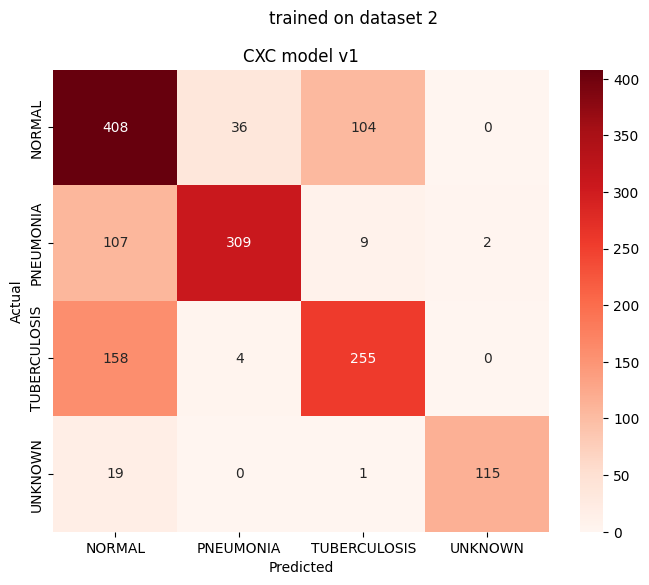

              precision    recall  f1-score   support

      NORMAL       0.59      0.74      0.66       548
   PNEUMONIA       0.89      0.72      0.80       427
TUBERCULOSIS       0.69      0.61      0.65       417
     UNKNOWN       0.98      0.85      0.91       135

    accuracy                           0.71      1527
   macro avg       0.79      0.73      0.75      1527
weighted avg       0.73      0.71      0.72      1527



In [13]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [14]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 255ms/step - accuracy: 0.7096 - loss: 0.7381
Test Loss: 0.738126277923584
Test Accuracy: 70.96%
